# Lab: Naive Bayes — **solution**

Companion notebook for the lecture *Probabilistic Model* (`slides/main.tex`).
This is the solution version: every `TODO` is filled in and every question has an answer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, beta
from scipy.special import logsumexp

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)          # fixed seed: everyone gets the same random numbers


def check(name, value, expected, tol=1e-3):
    """Print ✅ if value ≈ expected (element-wise), otherwise ❌."""
    try:
        ok = np.allclose(np.asarray(value, dtype=float), np.asarray(expected, dtype=float), atol=tol)
    except (TypeError, ValueError):
        ok = False
    print(("✅ " if ok else "❌ ") + name)

---
# Part 1 — Learning from Data: MLE
*Slides: Example: Coin Flipping · Coin Flip: Computing Likelihoods · MLE for a Bernoulli Parameter*

Two candidate coins: **straight** $\theta = p(H) = \tfrac12$ and **bent** $\theta = \tfrac45$.
Observed data $D$ = `HTHHHTHHTHTH`.

For i.i.d. flips the likelihood is $\;p(D\mid\theta) = \theta^{\#H}\,(1-\theta)^{\#T}$.

### 1.1 Count the data

In [2]:
flips = "HTHHHTHHTHTH"
n_heads = flips.count("H")
n_tails = flips.count("T")
print(f"{n_heads} heads, {n_tails} tails")
check("n_heads", n_heads, 8)
check("n_tails", n_tails, 4)

8 heads, 4 tails
✅ n_heads
✅ n_tails


### 1.2 Likelihood of each coin

In [3]:
def likelihood(theta, n_heads, n_tails):
    """p(D | theta) for i.i.d. Bernoulli flips."""
    return theta**n_heads * (1 - theta)**n_tails


lik_straight = likelihood(0.5, n_heads, n_tails)
lik_bent = likelihood(0.8, n_heads, n_tails)
print(f"p(D | straight) = {lik_straight:.3e}")
print(f"p(D | bent)     = {lik_bent:.3e}")
print(f"The data are {lik_bent / lik_straight:.2f}x more probable under the bent coin.")
check("p(D | straight)", lik_straight, 2.44e-4, tol=1e-6)
check("p(D | bent)", lik_bent, 2.68e-4, tol=1e-6)

p(D | straight) = 2.441e-04
p(D | bent)     = 2.684e-04
The data are 1.10x more probable under the bent coin.
✅ p(D | straight)
✅ p(D | bent)


> ⚠️ **Careful with the wording** (slide *Coin Flip: Computing Likelihoods*):
> this compares $p(D\mid\text{coin})$, **not** $p(\text{coin}\mid D)$.
> It does *not* say the bent coin is more likely to be the coin we are holding.

### 1.3 MLE when $\theta$ can be any value in $[0, 1]$
Evaluate $L(\theta)$ on a fine grid and pick the $\theta$ with the largest value.
Compare it with the closed form $\hat\theta = \#H / N$.

In [4]:
thetas = np.linspace(0, 1, 1001)
L = likelihood(thetas, n_heads, n_tails)      # our function also works on arrays
theta_hat = thetas[np.argmax(L)]
print(f"grid MLE = {theta_hat:.3f},   count / total = {n_heads / (n_heads + n_tails):.3f}")
check("theta_hat", theta_hat, 2 / 3)

grid MLE = 0.667,   count / total = 0.667
✅ theta_hat


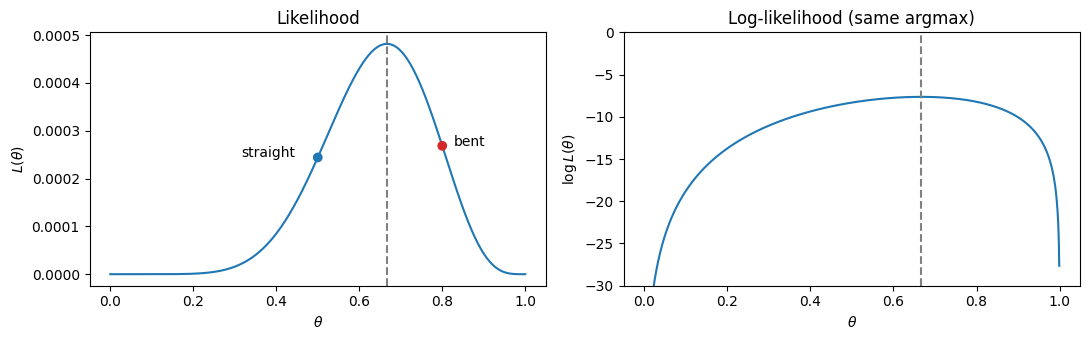

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(thetas, L)
ax[0].axvline(theta_hat, ls="--", c="gray")
ax[0].scatter([0.5, 0.8], [lik_straight, lik_bent], c=["tab:blue", "tab:red"], zorder=3)
ax[0].annotate("straight", (0.5, lik_straight), textcoords="offset points", xytext=(-55, 0))
ax[0].annotate("bent", (0.8, lik_bent), textcoords="offset points", xytext=(8, 0))
ax[0].set(xlabel=r"$\theta$", ylabel=r"$L(\theta)$", title="Likelihood")
with np.errstate(divide="ignore"):
    ax[1].plot(thetas, np.log(L))
ax[1].axvline(theta_hat, ls="--", c="gray")
ax[1].set(xlabel=r"$\theta$", ylabel=r"$\log L(\theta)$", ylim=(-30, 0),
          title="Log-likelihood (same argmax)")
plt.tight_layout()
plt.show()

### 1.4 Problem with MLE: little data
*Slide: Two Problems with MLE.* Flip a coin 3 times and get `HHH`.

In [6]:
theta_hhh = 3 / 3
print(f"MLE after HHH: p(H) = {theta_hhh},  p(T) = {1 - theta_hhh}")
check("MLE after HHH", theta_hhh, 1.0)

MLE after HHH: p(H) = 1.0,  p(T) = 0.0
✅ MLE after HHH


**Q1.** After only three flips, is it reasonable to say that tails is *impossible*?

> **Answer.** No. Three flips are very little evidence. MLE trusts the counts completely, so a value that was never seen gets probability 0. We fix this with smoothing (Part 3.6) and, more generally, with a prior on $\theta$ (Part 7).

### 🧪 Practice 1 — Free throws
A basketball player makes **7 of 10** free throws.
Coach A thinks the player's success rate is $\theta = 0.5$; Coach B thinks $\theta = 0.75$.

1. Compute the likelihood of the data under each coach's $\theta$. Which one does MLE choose?
2. What is the MLE $\hat\theta$ if $\theta$ can be any value in $[0, 1]$?

In [7]:
made, missed = 7, 3
lik_A = likelihood(0.5, made, missed)
lik_B = likelihood(0.75, made, missed)
theta_hat_ft = made / (made + missed)
print(f"p(D | 0.5) = {lik_A:.3e},  p(D | 0.75) = {lik_B:.3e},  theta_hat = {theta_hat_ft}")
check("p(D | theta=0.5)", lik_A, 9.766e-4, tol=1e-6)
check("p(D | theta=0.75)", lik_B, 2.086e-3, tol=1e-6)
check("theta_hat", theta_hat_ft, 0.7)

p(D | 0.5) = 9.766e-04,  p(D | 0.75) = 2.086e-03,  theta_hat = 0.7
✅ p(D | theta=0.5)
✅ p(D | theta=0.75)
✅ theta_hat


**Q2.** Which coach does MLE choose, and is the evidence strong?

> **Answer.** Coach B ($\theta = 0.75$): the data are about 2.1 times more probable under B. That is still weak evidence from only 10 shots.

---
# Part 2 — Bayes' Rule for Decisions
*Slides: Bayes' Rule · Back to the Coin · Computing the Posterior · How Much Does the Prior Matter?*

$$
\underbrace{p(h\mid D)}_{\text{posterior}} = \frac{p(D\mid h)\,p(h)}{p(D)}, \qquad p(D) = \sum_{h'} p(D\mid h')\,p(h')
$$

You will write **one** function `bayes()` here and reuse it for coins, patients, emails and documents.

In [8]:
def bayes(prior, lik):
    """Posterior over hypotheses: (likelihood × prior) / evidence."""
    prior = np.asarray(prior, dtype=float)
    lik = np.asarray(lik, dtype=float)
    joint = lik * prior
    evidence = joint.sum()
    return joint / evidence


# the coin came from a mint, so it is probably straight
prior_coin = [0.9, 0.1]                     # [straight, bent]
lik_coin = [lik_straight, lik_bent]
post_coin = bayes(prior_coin, lik_coin)
print(f"p(D) = {np.dot(prior_coin, lik_coin):.4e}")
print(f"p(straight | D) = {post_coin[0]:.3f},   p(bent | D) = {post_coin[1]:.3f}")
check("posterior", post_coin, [0.891, 0.109])

p(D) = 2.4657e-04
p(straight | D) = 0.891,   p(bent | D) = 0.109
✅ posterior


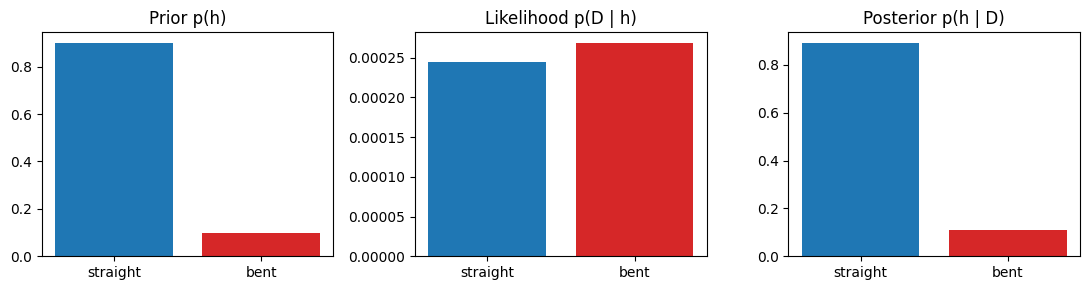

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, values, title in zip(axes, [prior_coin, lik_coin, post_coin],
                             ["Prior p(h)", "Likelihood p(D | h)", "Posterior p(h | D)"]):
    ax.bar(["straight", "bent"], values, color=["tab:blue", "tab:red"])
    ax.set_title(title)
plt.tight_layout()
plt.show()

### 2.1 How much does the prior matter? (reproduce the table on the slide)

In [10]:
rows = []
for pr in ([0.5, 0.5], [0.9, 0.1]):
    post = bayes(pr, lik_coin)
    rows.append({"prior (straight, bent)": pr, "posterior straight": post[0],
                 "posterior bent": post[1], "decision": ["straight", "bent"][np.argmax(post)]})
prior_table = pd.DataFrame(rows)
display(prior_table)
check("uniform prior", prior_table.loc[0, "posterior straight"], 0.476)
check("mint prior", prior_table.loc[1, "posterior straight"], 0.891)

,"prior (straight, bent)",posterior straight,posterior bent,decision
0,"[0.5, 0.5]",0.4763,0.5237,bent
1,"[0.9, 0.1]",0.8911,0.1089,straight


✅ uniform prior
✅ mint prior


**Q3.** With the uniform prior (0.5, 0.5) the decision is the same as MLE. Why?

> **Answer.** With a uniform prior, $p(h\mid D) \propto p(D\mid h) \cdot 0.5$, so the posterior is just the likelihood rescaled and the $\arg\max$ is the same.

### 2.2 With more data the likelihood wins
Suppose we keep flipping and see the same pattern $k$ times ($8k$ heads, $4k$ tails).
Keep the mint prior (0.9, 0.1). After how many repetitions does the posterior favour the bent coin?

The posterior first favours the bent coin at k = 24 (288 flips)
✅ k_switch


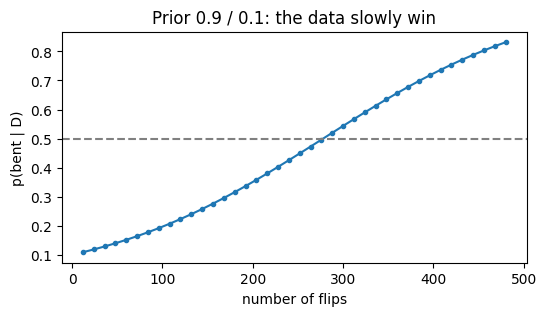

In [11]:
ks = np.arange(1, 41)
post_bent = []
for k in ks:
    lik_k = [likelihood(0.5, 8 * k, 4 * k), likelihood(0.8, 8 * k, 4 * k)]
    post_bent.append(bayes([0.9, 0.1], lik_k)[1])
post_bent = np.array(post_bent)

k_switch = ks[np.argmax(post_bent > 0.5)]
print(f"The posterior first favours the bent coin at k = {k_switch} ({12 * k_switch} flips)")
check("k_switch", k_switch, 24)

plt.figure(figsize=(6, 3))
plt.plot(12 * ks, post_bent, marker=".")
plt.axhline(0.5, ls="--", c="gray")
plt.xlabel("number of flips")
plt.ylabel("p(bent | D)")
plt.title("Prior 0.9 / 0.1: the data slowly win")
plt.show()

> 💡 Try `ks = np.arange(1, 201)`. What goes wrong at large $k$? (We fix it in Part 3.8.)

### 🧪 Practice 2 — A medical test
A disease affects **1%** of the population. A test has sensitivity $p(+\mid\text{disease}) = 0.95$
and false-positive rate $p(+\mid\text{no disease}) = 0.10$.

1. A patient tests positive. What is $p(\text{disease}\mid +)$?
2. The patient takes a second, independent test and is positive again. Update your belief
   (today's prior = yesterday's posterior).

In [12]:
prior_dz = [0.01, 0.99]                 # [disease, no disease]
lik_pos = [0.95, 0.10]                  # [p(+ | disease), p(+ | no disease)]
post_1 = bayes(prior_dz, lik_pos)
post_2 = bayes(post_1, lik_pos)
print(f"p(disease | +)    = {post_1[0]:.3f}")
print(f"p(disease | +, +) = {post_2[0]:.3f}")
check("after 1 test", post_1[0], 0.0876)
check("after 2 tests", post_2[0], 0.4769)

p(disease | +)    = 0.088
p(disease | +, +) = 0.477
✅ after 1 test
✅ after 2 tests


**Q4.** The test is 95% sensitive, yet $p(\text{disease}\mid +)$ is below 10%. Why?

> **Answer.** The prior is very small. Among 1000 people, about 10 have the disease (≈9.5 test positive) but about 99 healthy people also test positive. Most positives are false positives.

**Q5.** Updating twice with the same likelihood assumes something about the two test results. What? Where will this assumption appear again?

> **Answer.** That the two results are independent **given** the disease status: $p(+,+\mid h) = p(+\mid h)\,p(+\mid h)$. This is exactly the Naive Bayes assumption (Part 3).

---
# Part 3 — Bernoulli Naive Bayes
*Slides: Example: Problem Setup · Training Counts · Estimate the Class-Conditionals · Classify a New Patient*

Predict disease ($Y=1$) from three binary features: Fever, Cough, Fatigue.
Model: $X_i \mid Y=c \sim \text{Bernoulli}(\theta_{i|c})$ and
$\hat y = \arg\max_c\; p(Y=c)\prod_i p(x_i\mid Y=c)$.

In [13]:
df_train = pd.DataFrame({
    "Disease": [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0],
    "Fever":   [1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0],
    "Cough":   [1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0],
    "Fatigue": [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
})
features = ["Fever", "Cough", "Fatigue"]
df_train

,Disease,Fever,Cough,Fatigue
0,1,1,1,1
1,1,1,1,1
2,1,1,1,1
3,1,1,0,1
4,1,0,0,1
5,0,1,1,1
6,0,1,1,1
7,0,0,1,0
8,0,0,1,0
9,0,0,1,0


### 3.1 Training counts (the table on the slide)

In [14]:
N_c = df_train.groupby("Disease").size()
counts = df_train.groupby("Disease")[features].sum()
display(pd.concat([N_c.rename("N_c"), counts], axis=1).T)
check("N_c", N_c, [7, 5])
check("counts", counts, [[2, 5, 2], [4, 3, 5]])

Disease,0,1
N_c,7,5
Fever,2,4
Cough,5,3
Fatigue,2,5


✅ N_c
✅ counts


### 3.2 MLE: count / total
$\hat p(Y=c) = N_c / N \qquad \hat\theta_{i|c} = \text{count}(X_i=1, Y=c) / N_c$

Row 0 = no disease, row 1 = disease (sorted by label, the same order scikit-learn uses).

In [15]:
prior_y = N_c / N_c.sum()
theta = counts.div(N_c, axis=0)
display(theta)
check("prior", prior_y, [7 / 12, 5 / 12])
check("theta", theta, [[2 / 7, 5 / 7, 2 / 7], [0.8, 0.6, 1.0]])

,Fever,Cough,Fatigue
Disease,,,
0,0.2857,0.7143,0.2857
1,0.8000,0.6000,1.0000


✅ prior
✅ theta


> 💡 Shortcut: `df_train.groupby("Disease")[features].mean()` gives the same table, because the mean of 0/1 values is the proportion of 1s.

### 3.3 Classify a new patient $x = (1, 0, 1)$
$p(X_i = x_i\mid Y=c) = \theta_{i|c}$ if $x_i = 1$, and $1-\theta_{i|c}$ if $x_i = 0$.

In [16]:
def bernoulli_likelihood(x, theta):
    """p(x | Y=c) = prod_i p(X_i = x_i | Y=c), one value per class."""
    x = np.asarray(x)
    p = np.where(x == 1, theta, 1 - theta)
    return p.prod(axis=1)


x_new = [1, 0, 1]                                   # Fever=1, Cough=0, Fatigue=1
lik_x = bernoulli_likelihood(x_new, theta)
s_x = prior_y.values * lik_x
post_x = s_x / s_x.sum()
print("scores [s_0, s_1]:", s_x)
print("p(Y | x)         :", post_x)
check("s_1", s_x[1], 0.1333)
check("s_0", s_x[0], 0.0136)
check("p(Y=1 | x)", post_x[1], 0.907)

scores [s_0, s_1]: [0.0136 0.1333]
p(Y | x)         : [0.0926 0.9074]
✅ s_1
✅ s_0
✅ p(Y=1 | x)


### 3.4 Problem: zero probabilities
*Slide: Problem: Zero Probabilities.* All 5 disease patients had fatigue, so $\hat p(\text{Fatigue}=0\mid Y=1) = 0$.
Classify another patient $x = (1, 1, 0)$.

In [17]:
x_new2 = [1, 1, 0]                                  # Fever=1, Cough=1, Fatigue=0
lik_x2 = bernoulli_likelihood(x_new2, theta)
s_x2 = prior_y.values * lik_x2
print("scores [s_0, s_1]:", s_x2, "  p(Y | x):", s_x2 / s_x2.sum())
check("s_1 is vetoed", s_x2[1], 0.0)
check("s_0", s_x2[0], 0.0850)

scores [s_0, s_1]: [0.085 0.   ]   p(Y | x): [1. 0.]
✅ s_1 is vetoed
✅ s_0


**Q6.** Fever and cough are both present. Is $p(Y=1\mid x) = 0$ a sensible answer?

> **Answer.** No. One unseen value (Fatigue = 0 among only 5 disease patients) vetoes the whole product, whatever the other features say. This is the HHH problem from Part 1 again.

### 3.5 Laplace (add-$\alpha$) smoothing
*Slides: Laplace Smoothing · Example with Laplace Smoothing*

$$\hat p_\alpha(X_i = 1\mid Y=c) = \frac{\text{count}(X_i=1, Y=c) + \alpha}{N_c + \alpha K}, \qquad K = 2 \text{ for binary features}$$

The class priors are **not** smoothed (they stay $7/12$ and $5/12$).

In [18]:
def fit_bernoulli_nb(df, features, target, alpha=1.0):
    """Return (prior, theta) where theta[c, i] = p(X_i = 1 | Y = c) with add-alpha smoothing."""
    N_c = df.groupby(target).size()
    counts = df.groupby(target)[features].sum()
    prior = N_c / N_c.sum()
    theta = (counts + alpha).div(N_c + 2 * alpha, axis=0)
    return prior, theta


prior_s, theta_s = fit_bernoulli_nb(df_train, features, "Disease", alpha=1)
display(theta_s)
check("theta (smoothed)", theta_s, [[3 / 9, 6 / 9, 3 / 9], [5 / 7, 4 / 7, 6 / 7]])

,Fever,Cough,Fatigue
Disease,,,
0,0.3333,0.6667,0.3333
1,0.7143,0.5714,0.8571


✅ theta (smoothed)


In [19]:
rows = []
for x in ([1, 1, 0], [1, 0, 1]):
    p_mle = bayes(prior_y, bernoulli_likelihood(x, theta))[1]
    p_smooth = bayes(prior_s, bernoulli_likelihood(x, theta_s))[1]
    rows.append({"x": x, "p(Y=1|x) no smoothing": p_mle, "p(Y=1|x) Laplace": p_smooth})
smooth_table = pd.DataFrame(rows)
display(smooth_table)
check("x=(1,1,0) smoothed", smooth_table.iloc[0, 2], 0.219)
check("x=(1,0,1) smoothed", smooth_table.iloc[1, 2], 0.835)

,x,p(Y=1|x) no smoothing,p(Y=1|x) Laplace
0,"[1, 1, 0]",0.0000,0.2194
1,"[1, 0, 1]",0.9074,0.8350


✅ x=(1,1,0) smoothed
✅ x=(1,0,1) smoothed


### 3.6 How does $\alpha$ change the answer?

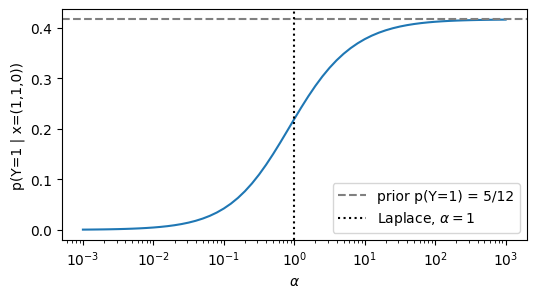

In [20]:
alphas = np.logspace(-3, 3, 61)
p_110 = []
for a in alphas:
    pr, th = fit_bernoulli_nb(df_train, features, "Disease", alpha=a)
    p_110.append(bayes(pr, bernoulli_likelihood([1, 1, 0], th))[1])

plt.figure(figsize=(6, 3))
plt.semilogx(alphas, p_110)
plt.axhline(5 / 12, ls="--", c="gray", label="prior p(Y=1) = 5/12")
plt.axvline(1, ls=":", c="k", label=r"Laplace, $\alpha = 1$")
plt.xlabel(r"$\alpha$")
plt.ylabel("p(Y=1 | x=(1,1,0))")
plt.legend()
plt.show()

**Q7.** What happens when $\alpha \to 0$ and when $\alpha \to \infty$? Why does the curve approach the prior?

> **Answer.** $\alpha \to 0$ gives back MLE, so $p(Y=1\mid x) \to 0$. When $\alpha \to \infty$, every $\hat\theta_{i|c} \to 1/2$ for both classes, so the features no longer tell the classes apart and the posterior falls back to the prior $5/12$. $\alpha$ controls how much we trust the counts.

### 3.7 The same model in scikit-learn
*Slide: In Practice — "Libraries such as scikit-learn do this internally."*

In [21]:
from sklearn.naive_bayes import BernoulliNB

X_train = df_train[features].to_numpy()
y_train = df_train["Disease"].to_numpy()
X_test = np.array([[1, 0, 1], [1, 1, 0]])

bnb = BernoulliNB(alpha=1.0)
bnb.fit(X_train, y_train)

print("classes_        :", bnb.classes_)
print("p(Y=c)          :", np.exp(bnb.class_log_prior_))      # sklearn stores log-probabilities
print("p(X_i=1 | Y=c)  :\n", np.exp(bnb.feature_log_prob_))
print("p(Y | x)        :\n", bnb.predict_proba(X_test))
check("sklearn theta = our theta_s", np.exp(bnb.feature_log_prob_), theta_s)
check("sklearn p(Y=1|x)", bnb.predict_proba(X_test)[:, 1], [0.835, 0.219])

classes_        : [0 1]
p(Y=c)          : [0.5833 0.4167]
p(X_i=1 | Y=c)  :
 [[0.3333 0.6667 0.3333]
 [0.7143 0.5714 0.8571]]
p(Y | x)        :
 [[0.165  0.835 ]
 [0.7806 0.2194]]
✅ sklearn theta = our theta_s
✅ sklearn p(Y=1|x)


> Note: `bnb.class_prior` is the prior *you pass in* (default `None`); the fitted prior is
> `np.exp(bnb.class_log_prior_)`.

**What about $\alpha = 0$ (pure MLE) in scikit-learn?**

In [22]:
bnb0 = BernoulliNB(alpha=0.0).fit(X_train, y_train)
print("alpha = 0     :", bnb0.predict_proba(X_test))

bnb_tiny = BernoulliNB(alpha=1e-10).fit(X_train, y_train)
print("alpha = 1e-10 :", bnb_tiny.predict_proba(X_test))
check("tiny alpha reproduces MLE", bnb_tiny.predict_proba(X_test)[:, 1], [0.907, 0.0])

alpha = 0     : [[nan nan]
 [nan nan]]
alpha = 1e-10 : [[0.0926 0.9074]
 [1.     0.    ]]
✅ tiny alpha reproduces MLE


C:\Users\dream\miniconda3\envs\ds\Lib\site-packages\sklearn\naive_bayes.py:1256: RuntimeWarning: divide by zero encountered in log
  neg_prob = np.log(1 - np.exp(self.feature_log_prob_))
C:\Users\dream\miniconda3\envs\ds\Lib\site-packages\sklearn\utils\extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
C:\Users\dream\miniconda3\envs\ds\Lib\site-packages\sklearn\naive_bayes.py:1259: RuntimeWarning: invalid value encountered in add
  jll += self.class_log_prior_ + neg_prob.sum(axis=1)
C:\Users\dream\miniconda3\envs\ds\Lib\site-packages\sklearn\utils\_array_api.py:1362: RuntimeWarning: divide by zero encountered in log
  out = xp.log1p(s) + xp.log(m) + array_max


**Q8.** Why does $\alpha = 0$ give `nan` (and a `divide by zero encountered in log` warning) instead of 0.907?

> **Answer.** scikit-learn works in log space and uses both $\log\theta$ and $\log(1-\theta)$. For Fatigue in the disease class $\theta = 1$, so $\log(1-\theta) = \log 0 = -\infty$, and $-\infty + \infty$ terms give `nan`. A tiny $\alpha$ avoids the exact zero. Lesson: never silence warnings with `warnings.filterwarnings('ignore')`; they often point to a real problem.

### 3.8 Work in log space
*Slide: In Practice: Work in Log Space.* A product of many small probabilities underflows to 0.

In [23]:
p_words = np.full(500, 1e-3)            # a 500-word document, each word has probability 1e-3
product = np.prod(p_words)
log_sum = np.sum(np.log(p_words))
print("product     :", product)
print("sum of logs :", log_sum)
check("product underflows", product, 0.0)
check("sum of logs", log_sum, -3453.88, tol=0.01)

product     : 0.0
sum of logs : -3453.8776394910683
✅ product underflows
✅ sum of logs


Now redo Naive Bayes in log space:
$\log s_c = \log p(Y=c) + \sum_i \log p(x_i\mid Y=c)$.
To turn log-scores into probabilities safely, use
$p(Y=c\mid x) = \exp\big(\log s_c - \text{logsumexp}(\log s)\big)$.

In [24]:
def bernoulli_log_likelihood(x, theta):
    x = np.asarray(x)
    log_p = np.where(x == 1, np.log(theta), np.log(1 - theta))
    return log_p.sum(axis=1)


log_s = np.log(prior_s.values) + bernoulli_log_likelihood(x_new, theta_s)
post_log = np.exp(log_s - logsumexp(log_s))
print("log scores (ours)   :", log_s)
print("log scores (sklearn):", bnb.predict_joint_log_proba([x_new])[0])
print("p(Y | x)            :", post_log)
check("log scores = sklearn", log_s, bnb.predict_joint_log_proba([x_new])[0])
check("p(Y=1 | x)", post_log[1], 0.835)

log scores (ours)   : [-3.8348 -2.2134]
log scores (sklearn): [-3.8348 -2.2134]
p(Y | x)            : [0.165 0.835]
✅ log scores = sklearn
✅ p(Y=1 | x)


**Back to Part 2.2:** with $k = 200$ repetitions (2400 flips) the direct computation breaks.
Redo it in log space.

In [25]:
def log_likelihood(theta, n_heads, n_tails):
    return n_heads * np.log(theta) + n_tails * np.log(1 - theta)


k = 200
direct = bayes([0.9, 0.1], [likelihood(0.5, 8 * k, 4 * k), likelihood(0.8, 8 * k, 4 * k)])
log_s_coin = np.log([0.9, 0.1]) + np.array([log_likelihood(0.5, 8 * k, 4 * k),
                                            log_likelihood(0.8, 8 * k, 4 * k)])
post_k = np.exp(log_s_coin - logsumexp(log_s_coin))
print("direct    :", direct)
print("log space :", post_k)
check("p(bent | D), k=200", post_k[1], 1.0)

direct    : [nan nan]
log space : [0. 1.]
✅ p(bent | D), k=200


C:\Users\dream\AppData\Local\Temp\ipykernel_1864\669365956.py:7: RuntimeWarning: invalid value encountered in divide
  return joint / evidence


### 🧪 Practice 3 — A tiny spam filter (Bernoulli NB)
Each email is described by whether it **contains** the words *free*, *winner*, *meeting*.

1. Fit Bernoulli NB with $\alpha = 1$ (reuse `fit_bernoulli_nb`) and compute
   $p(\text{spam}\mid \text{free}=1, \text{winner}=0, \text{meeting}=1)$.
2. Check your answer against `BernoulliNB`.
3. Fit again with $\alpha = 0$ and classify $x = (0, 1, 1)$. What happens? Why?

In [26]:
df_email = pd.DataFrame({
    "Spam":    [1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
    "free":    [1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
    "winner":  [1, 0, 1, 1, 0, 0, 0, 0, 0, 0],
    "meeting": [0, 0, 0, 0, 1, 1, 1, 0, 1, 0],
})
words = ["free", "winner", "meeting"]
df_email

,Spam,free,winner,meeting
0,1,1,1,0
1,1,1,0,0
2,1,1,1,0
3,1,0,1,0
4,0,1,0,1
5,0,0,0,1
6,0,0,0,1
7,0,0,0,0
8,0,0,0,1
9,0,0,0,0


In [27]:
# 1. by hand
prior_e, theta_e = fit_bernoulli_nb(df_email, words, "Spam", alpha=1)
x_email = [1, 0, 1]
post_e = bayes(prior_e, bernoulli_likelihood(x_email, theta_e))
print(f"p(spam | x) = {post_e[1]:.3f}")

# 2. scikit-learn
bnb_e = BernoulliNB(alpha=1).fit(df_email[words].to_numpy(), df_email["Spam"].to_numpy())
print("sklearn     :", bnb_e.predict_proba([x_email])[0])
check("matches sklearn", post_e, bnb_e.predict_proba([x_email])[0])

p(spam | x) = 0.153
sklearn     : [0.847 0.153]
✅ matches sklearn


In [28]:
# 3. alpha = 0 and x = (0, 1, 1)
prior_0, theta_0 = fit_bernoulli_nb(df_email, words, "Spam", alpha=0)
s_0 = prior_0.values * bernoulli_likelihood([0, 1, 1], theta_0)
print("scores with alpha=0:", s_0, "  posterior:", s_0 / s_0.sum())

prior_1, theta_1 = fit_bernoulli_nb(df_email, words, "Spam", alpha=1)
print("posterior with alpha=1:", bayes(prior_1, bernoulli_likelihood([0, 1, 1], theta_1)))

scores with alpha=0: [0. 0.]   posterior: [nan nan]
posterior with alpha=1: [0.7035 0.2965]


C:\Users\dream\AppData\Local\Temp\ipykernel_1864\537527781.py:4: RuntimeWarning: invalid value encountered in divide
  print("scores with alpha=0:", s_0, "  posterior:", s_0 / s_0.sum())


**Q9.** Explain the result for $\alpha = 0$.

> **Answer.** *meeting* never appears in spam and *winner* never appears in ham, so with MLE both scores are 0. The posterior is $0/0$ = `nan`: the model cannot decide at all. With $\alpha = 1$ both scores are positive and $p(\text{spam}\mid x) \approx 0.30$.

---
# Part 4 — Naive Bayes Variants
Pick the distribution of each feature (given the class) to match the type of data.

## 4.1 Categorical Naive Bayes
*Slide: Naive Bayes Variants: Discrete Features.* (New example.)

Predict whether a student is **late** for class ($Y=1$) from *Weather* $\in$ {sunny, cloudy, rainy}
and *Transport* $\in$ {bus, car, walk}.

$$\hat\theta_{i,k|c} = \frac{\text{count}(X_i = k, Y = c) + \alpha}{N_c + \alpha K_i}$$

In [29]:
df_late = pd.DataFrame({
    "Late":      [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0],
    "Weather":   ["rainy", "rainy", "rainy", "cloudy", "sunny",
                  "sunny", "sunny", "sunny", "cloudy", "cloudy", "rainy", "sunny"],
    "Transport": ["bus", "bus", "car", "bus", "bus",
                  "walk", "car", "bus", "walk", "car", "walk", "walk"],
})
pd.crosstab(df_late["Late"], df_late["Transport"])      # counts per class and value

Transport,bus,car,walk
Late,,,
0,1,2,4
1,4,1,0


In [30]:
def categorical_table(df, feature, target, alpha=1.0):
    """p(X_i = k | Y = c): one row per class c, one column per value k."""
    counts = pd.crosstab(df[target], df[feature])      # count(X_i = k, Y = c)
    N_c = counts.sum(axis=1)
    K = counts.shape[1]
    return (counts + alpha).div(N_c + alpha * K, axis=0)


tables = {f: categorical_table(df_late, f, "Late") for f in ["Weather", "Transport"]}
display(tables["Weather"], tables["Transport"])
check("p(walk | late)", tables["Transport"].loc[1, "walk"], 1 / 8)

Weather,cloudy,rainy,sunny
Late,,,
0,0.30,0.2,0.50
1,0.25,0.5,0.25


Transport,bus,car,walk
Late,,,
0,0.200,0.30,0.500
1,0.625,0.25,0.125


✅ p(walk | late)


In [31]:
prior_late = df_late["Late"].value_counts(normalize=True).sort_index()
x_cat = {"Weather": "rainy", "Transport": "walk"}
lik_cat = tables["Weather"][x_cat["Weather"]] * tables["Transport"][x_cat["Transport"]]
post_late = bayes(prior_late, lik_cat)
print(f"p(late | rainy, walk) = {post_late[1]:.3f}")
check("p(late | rainy, walk)", post_late[1], 0.309)

p(late | rainy, walk) = 0.309
✅ p(late | rainy, walk)


In [32]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder

enc = OrdinalEncoder()                              # categories -> 0, 1, 2 (alphabetical)
X_late = enc.fit_transform(df_late[["Weather", "Transport"]])
catnb = CategoricalNB(alpha=1).fit(X_late, df_late["Late"])
print("categories:", enc.categories_)

x_cat_enc = enc.transform(pd.DataFrame([x_cat]))
print("sklearn p(Y | rainy, walk):", catnb.predict_proba(x_cat_enc)[0])
check("sklearn agrees", catnb.predict_proba(x_cat_enc)[0], post_late)

categories: [array(['cloudy', 'rainy', 'sunny'], dtype=object), array(['bus', 'car', 'walk'], dtype=object)]
sklearn p(Y | rainy, walk): [0.6914 0.3086]
✅ sklearn agrees


**Your turn:** compute $p(\text{late}\mid \text{sunny}, \text{car})$ by hand and check it with `catnb`.

In [33]:
x_cat2 = {"Weather": "sunny", "Transport": "car"}
post_late2 = bayes(prior_late, tables["Weather"][x_cat2["Weather"]] * tables["Transport"][x_cat2["Transport"]])
print(f"p(late | sunny, car) = {post_late2[1]:.3f}")
check("matches CategoricalNB", post_late2, catnb.predict_proba(enc.transform(pd.DataFrame([x_cat2])))[0])

p(late | sunny, car) = 0.229
✅ matches CategoricalNB


**Q10.** Why not encode sunny = 0, cloudy = 1, rainy = 2 and use Gaussian NB instead?

> **Answer.** The values have no order or distance: "rainy" is not "twice cloudy". A Normal distribution over 0/1/2 would impose a shape that means nothing. Categorical NB gives every value its own probability.

## 4.2 Gaussian Naive Bayes
*Slides: Gaussian Naive Bayes · Example: Gaussian Naive Bayes*

Predict flu ($Y=1$) from temperature $X_1$ and heart rate $X_2$:
$X_i\mid Y=c \sim \mathcal N(\mu_{i|c}, \sigma^2_{i|c})$.

> ⚠️ In `scipy.stats.norm.pdf(x, loc, scale)`, `scale` is the **standard deviation** $\sigma$, not $\sigma^2$.

In [34]:
params = pd.DataFrame({
    "prior":   [0.7, 0.3],
    "mu_temp": [37.0, 38.5], "sd_temp": [0.5, 0.5],
    "mu_hr":   [75.0, 95.0], "sd_hr":   [10.0, 10.0],
}, index=pd.Index([0, 1], name="Flu"))
params

,prior,mu_temp,sd_temp,mu_hr,sd_hr
Flu,,,,,
0,0.7,37.0,0.5,75.0,10.0
1,0.3,38.5,0.5,95.0,10.0


In [35]:
x_temp, x_hr = 38.0, 80
dens_temp = norm.pdf(x_temp, loc=params["mu_temp"], scale=params["sd_temp"])
dens_hr = norm.pdf(x_hr, loc=params["mu_hr"], scale=params["sd_hr"])
s_flu = params["prior"].to_numpy() * dens_temp * dens_hr
post_flu = s_flu / s_flu.sum()
print("density temp :", dens_temp)
print("density HR   :", dens_hr)
print("scores       :", s_flu)
print("p(Y | x)     :", post_flu)
check("N(38.0; 38.5, 0.5^2)", dens_temp[1], 0.484)
check("N(80; 75, 10^2)", dens_hr[0], 0.0352)
check("p(flu | x)", post_flu[1], 0.41, tol=0.01)

density temp : [0.108  0.4839]
density HR   : [0.0352 0.013 ]
scores       : [0.0027 0.0019]
p(Y | x)     : [0.586 0.414]
✅ N(38.0; 38.5, 0.5^2)
✅ N(80; 75, 10^2)
✅ p(flu | x)


**Q11.** `norm.pdf(38.5, 38.5, 0.1)` is about 3.99. How can a "probability" be larger than 1? Is it a problem for Naive Bayes?

> **Answer.** It is a **density**, not a probability: only its integral must be 1. It is not a problem, because Bayes' rule only compares and normalizes the scores across classes.

### A generative model can generate data
*Slide: Generative vs Discriminative — "can generate new examples $x \sim p(X\mid Y=c)$".*
Sample 2000 patients from the model above, then let `GaussianNB` learn the parameters back.

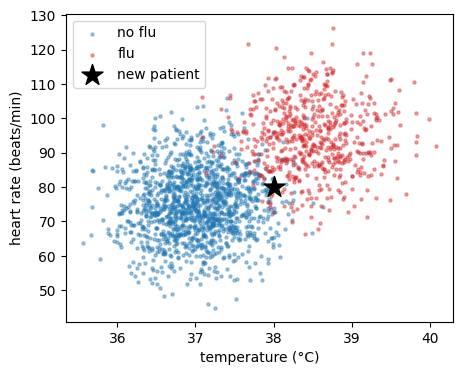

In [36]:
N_flu = 2000
mu = params[["mu_temp", "mu_hr"]].to_numpy()        # shape (2 classes, 2 features)
sd = params[["sd_temp", "sd_hr"]].to_numpy()
y_flu = (rng.random(N_flu) < 0.3).astype(int)
X_flu = rng.normal(mu[y_flu], sd[y_flu])

plt.figure(figsize=(5, 4))
for c, color in [(0, "tab:blue"), (1, "tab:red")]:
    plt.scatter(*X_flu[y_flu == c].T, s=5, alpha=0.4, c=color, label=["no flu", "flu"][c])
plt.scatter([x_temp], [x_hr], marker="*", s=250, c="k", label="new patient")
plt.xlabel("temperature (°C)")
plt.ylabel("heart rate (beats/min)")
plt.legend()
plt.show()

In [37]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB().fit(X_flu, y_flu)
print("learned prior:", gnb.class_prior_)
print("learned mu   :\n", gnb.theta_)
print("learned sd   :\n", np.sqrt(gnb.var_))
print("p(Y | 38.0, 80):", gnb.predict_proba([[x_temp, x_hr]])[0])
check("learned mu ≈ true mu", gnb.theta_, mu, tol=1.0)
check("p(flu | x) ≈ 0.41", gnb.predict_proba([[x_temp, x_hr]])[0, 1], 0.41, tol=0.05)

learned prior: [0.698 0.302]
learned mu   :
 [[37.0144 75.1013]
 [38.4959 94.7443]]
learned sd   :
 [[ 0.4947  9.8456]
 [ 0.5026 10.1824]]
p(Y | 38.0, 80): [0.5778 0.4222]
✅ learned mu ≈ true mu
✅ p(flu | x) ≈ 0.41


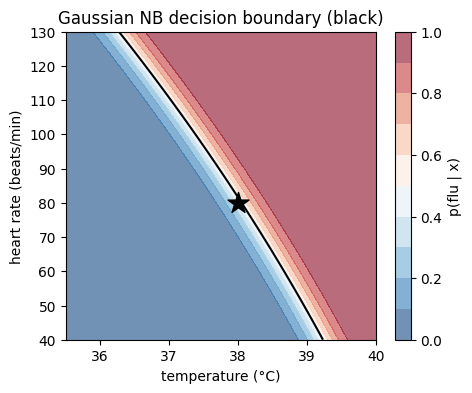

In [38]:
tt, hh = np.meshgrid(np.linspace(35.5, 40, 200), np.linspace(40, 130, 200))
P = gnb.predict_proba(np.column_stack([tt.ravel(), hh.ravel()]))[:, 1].reshape(tt.shape)

plt.figure(figsize=(5, 4))
cs = plt.contourf(tt, hh, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
plt.contour(tt, hh, P, levels=[0.5], colors="k")
plt.colorbar(cs, label="p(flu | x)")
plt.scatter([x_temp], [x_hr], marker="*", s=250, c="k")
plt.xlabel("temperature (°C)")
plt.ylabel("heart rate (beats/min)")
plt.title("Gaussian NB decision boundary (black)")
plt.show()

**Q12 (optional).** The boundary is (almost) a straight line. Why? *Hint: compare $\sigma$ between the two classes.*

> **Answer.** Both classes have the same $\sigma$ for each feature. Then the quadratic terms in $\log s_1 - \log s_0$ cancel and the log-odds are linear in $x$, the same form as logistic regression. With different variances per class the boundary would be curved.

## 4.3 Multinomial Naive Bayes
*Slides: Multinomial Naive Bayes · Example · Estimates · Classify*

Documents → bag of words (counts). $\hat\theta_{w|c} = \dfrac{\text{count}(w,c)+\alpha}{\sum_{w'}\text{count}(w',c)+\alpha d}$,
$\;s_c = p(Y=c)\prod_w \theta_{w|c}^{x_w}$.

The four training documents below add up to the word counts on the slide.

In [39]:
from sklearn.feature_extraction.text import CountVectorizer

docs = [
    "apple apple banana orange",            # Topic A
    "apple apple banana banana orange",     # Topic A
    "banana banana banana orange",          # Topic B
    "apple banana banana orange",           # Topic B
]
y_doc = np.array([1, 1, 0, 0])              # 1 = Topic A, 0 = Topic B

vec = CountVectorizer()
X_doc = vec.fit_transform(docs).toarray()   # one row per document, one column per word
vocab = vec.get_feature_names_out()
pd.DataFrame(X_doc, columns=vocab)

,apple,banana,orange
0,2,1,1
1,2,2,1
2,0,3,1
3,1,2,1


In [40]:
count_A = X_doc[y_doc == 1].sum(axis=0)
count_B = X_doc[y_doc == 0].sum(axis=0)
word_counts = pd.DataFrame({"Topic A": count_A, "Topic B": count_B}, index=vocab)
word_counts.loc["Total words"] = word_counts.sum()
display(word_counts)
check("Topic A counts", count_A, [4, 3, 2])
check("Topic B counts", count_B, [1, 5, 2])

,Topic A,Topic B
apple,4,1
banana,3,5
orange,2,2
Total words,9,8


✅ Topic A counts
✅ Topic B counts


In [41]:
alpha, d = 1, len(vocab)
theta_A = (count_A + alpha) / (count_A.sum() + alpha * d)
theta_B = (count_B + alpha) / (count_B.sum() + alpha * d)
print("theta_A:", theta_A, "  theta_B:", theta_B)
check("theta_A", theta_A, [5 / 12, 4 / 12, 3 / 12])
check("theta_B", theta_B, [2 / 11, 6 / 11, 3 / 11])

theta_A: [0.4167 0.3333 0.25  ]   theta_B: [0.1818 0.5455 0.2727]
✅ theta_A
✅ theta_B


In [42]:
x_doc = vec.transform(["apple orange orange"]).toarray()[0]     # apple=1, banana=0, orange=2
s_A = 0.5 * np.prod(theta_A ** x_doc)
s_B = 0.5 * np.prod(theta_B ** x_doc)
post_A = s_A / (s_A + s_B)
print(f"x = {x_doc},  s_A = {s_A:.4f},  s_B = {s_B:.4f},  p(Topic A | doc) = {post_A:.3f}")
check("s_A", s_A, 45 / 3456, tol=1e-5)
check("s_B", s_B, 18 / 2662, tol=1e-5)
check("p(Topic A | doc)", post_A, 0.658)

x = [1 0 2],  s_A = 0.0130,  s_B = 0.0068,  p(Topic A | doc) = 0.658
✅ s_A
✅ s_B
✅ p(Topic A | doc)


In [43]:
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB(alpha=1).fit(X_doc, y_doc)
print("feature_count_ (rows: B, A):\n", mnb.feature_count_)
print("p(w | c):\n", np.exp(mnb.feature_log_prob_))
print("p(Y | doc):", mnb.predict_proba([x_doc])[0])
check("sklearn p(Topic A | doc)", mnb.predict_proba([x_doc])[0, 1], post_A)

feature_count_ (rows: B, A):
 [[1. 5. 2.]
 [4. 3. 2.]]
p(w | c):
 [[0.1818 0.5455 0.2727]
 [0.4167 0.3333 0.25  ]]
p(Y | doc): [0.3418 0.6582]
✅ sklearn p(Topic A | doc)


> scikit-learn's prior is (number of documents in $c$) / (total documents) = 2/4 = 0.5,
> the same simplification as on the slide.

## 4.4 Complement Naive Bayes (optional)
*Slide: Complement Naive Bayes.* For each class $c$, estimate the word distribution of its
**complement** $\neg c$, then choose the class whose complement fits the document **worst**:
$\hat y = \arg\max_c \; -\sum_w x_w \log\hat\theta_{w|\neg c}$.

In [44]:
theta_notA = theta_B                    # with 2 classes, the complement of A is B
theta_notB = theta_A
score_A = -np.sum(x_doc * np.log(theta_notA))
score_B = -np.sum(x_doc * np.log(theta_notB))
print(f"CNB scores: A = {score_A:.3f}, B = {score_B:.3f}  ->", "Topic A" if score_A > score_B else "Topic B")

from sklearn.naive_bayes import ComplementNB
compnb = ComplementNB(alpha=1).fit(X_doc, y_doc)
print("ComplementNB  p(Y | doc):", compnb.predict_proba([x_doc])[0])
print("MultinomialNB p(Y | doc):", mnb.predict_proba([x_doc])[0])
check("sklearn stores -log theta_not_c", compnb.feature_log_prob_, -np.log([theta_notB, theta_notA]))

CNB scores: A = 4.303, B = 3.648  -> Topic A
ComplementNB  p(Y | doc): [0.3418 0.6582]
MultinomialNB p(Y | doc): [0.3418 0.6582]
✅ sklearn stores -log theta_not_c


**Q13.** Why do ComplementNB and MultinomialNB give exactly the same answer here?

> **Answer.** With only 2 classes the complement of A is B and vice versa, and the priors are equal, so the two rules are the same comparison. CNB only helps with 3 or more (imbalanced) classes.

### 🧪 Practice 4 — SMS spam with Multinomial NB
1. Turn the messages into word counts with `CountVectorizer` and fit `MultinomialNB(alpha=1)`.
2. Compute $p(\text{spam})$ for the three new messages.
3. List the 5 most "spammy" words, i.e. the largest $\log\hat\theta_{w|\text{spam}} - \log\hat\theta_{w|\text{ham}}$.

In [45]:
sms = [
    ("win a free prize now", 1),
    ("free entry win cash now", 1),
    ("claim your free prize call now", 1),
    ("urgent you win cash claim now", 1),
    ("free free free call now", 1),
    ("are we meeting for lunch today", 0),
    ("call me when you get home", 0),
    ("lunch at noon see you there", 0),
    ("can you send the report today", 0),
    ("see you at the meeting", 0),
    ("i will call you tonight", 0),
    ("thanks for lunch today", 0),
]
sms_text = [t for t, _ in sms]
sms_y = np.array([label for _, label in sms])      # 1 = spam, 0 = ham
new_sms = ["free lunch today", "call now to claim your prize", "see you tonight"]

In [46]:
vec_sms = CountVectorizer()
X_sms = vec_sms.fit_transform(sms_text)
mnb_sms = MultinomialNB(alpha=1).fit(X_sms, sms_y)
p_spam = mnb_sms.predict_proba(vec_sms.transform(new_sms))[:, 1]
display(pd.DataFrame({"message": new_sms, "p(spam)": p_spam}))

log_ratio = mnb_sms.feature_log_prob_[1] - mnb_sms.feature_log_prob_[0]
top5 = vec_sms.get_feature_names_out()[np.argsort(log_ratio)[::-1][:5]]
print("most spammy words:", top5)

,message,p(spam)
0,free lunch today,0.3448
1,call now to claim your prize,0.9946
2,see you tonight,0.0626


most spammy words: ['free' 'now' 'win' 'prize' 'cash']


**Q14.** (a) What does `CountVectorizer` do with a word it never saw in training (e.g. *to* in "call now to claim your prize")? (b) *lunch* never appears in spam. What would $\alpha = 0$ predict for "free lunch today"?

> **Answer.** (a) It is ignored: it has no column in the vocabulary, so it adds nothing to either score. (b) $\hat\theta_{\text{lunch}|\text{spam}} = 0$, so the spam score is 0 and $p(\text{spam}) = 0$ however many times *free* appears. Smoothing again.

---
# Part 5 — Naive Bayes in Practice: Generative vs Discriminative
*Slides: Naive Bayes: Summary · Generative vs Discriminative Classifiers*

Breast-cancer data (built into scikit-learn, no download): 30 continuous features, target 1 = benign, 0 = malignant.
Compare **Gaussian NB** (generative) with **logistic regression** (discriminative).

In [47]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss

data = load_breast_cancer(as_frame=True)
X_bc, y_bc = data.data, data.target
X_tr, X_te, y_tr, y_te = train_test_split(X_bc, y_bc, test_size=0.3, random_state=0, stratify=y_bc)
print(X_bc.shape, y_bc.value_counts().to_dict())

(569, 30) {1: 357, 0: 212}


In [48]:
gnb_bc = GaussianNB().fit(X_tr, y_tr)
lr_bc = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)

rows = []
for name, model in [("Gaussian NB", gnb_bc), ("Logistic regression", lr_bc)]:
    p = model.predict_proba(X_te)[:, 1]
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_te, model.predict(X_te)),
                 "log loss": log_loss(y_te, p),
                 "% p<0.01 or p>0.99": 100 * np.mean((p < 0.01) | (p > 0.99))})
pd.DataFrame(rows)

,model,accuracy,log loss,% p<0.01 or p>0.99
0,Gaussian NB,0.9240,1.0899,95.3216
1,Logistic regression,0.9591,0.0846,71.9298


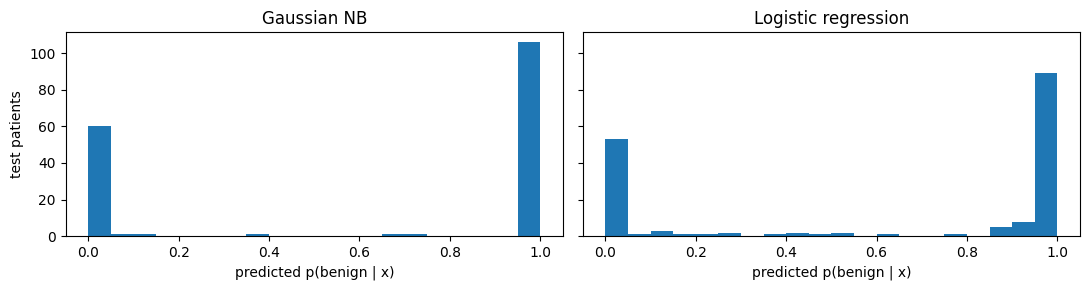

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, (name, model) in zip(axes, [("Gaussian NB", gnb_bc), ("Logistic regression", lr_bc)]):
    ax.hist(model.predict_proba(X_te)[:, 1], bins=20, range=(0, 1))
    ax.set(title=name, xlabel="predicted p(benign | x)")
axes[0].set_ylabel("test patients")
plt.tight_layout()
plt.show()

Accuracy is similar, but Naive Bayes is **over-confident**: it puts almost every prediction at 0 or 1,
*including some of its mistakes*. A confident wrong answer is punished heavily, so its log loss is
more than 10 times worse. *Slide: "Correlated features are counted twice."*

In [50]:
X_bc[["mean radius", "mean perimeter", "mean area"]].corr()

,mean radius,mean perimeter,mean area
mean radius,1.0000,0.9979,0.9874
mean perimeter,0.9979,1.0000,0.9865
mean area,0.9874,0.9865,1.0000


### 🧪 Practice 5 — Counting the same evidence twice
Radius, perimeter and area measure almost the same thing. Train Gaussian NB on
(a) `mean radius, mean texture` and (b) the same plus `mean perimeter, mean area`.
Compare accuracy, log loss and the share of extreme predictions.

In [51]:
def nb_report(cols):
    model = GaussianNB().fit(X_tr[cols], y_tr)
    p = model.predict_proba(X_te[cols])[:, 1]
    return {"features": ", ".join(cols),
            "accuracy": accuracy_score(y_te, (p > 0.5).astype(int)),
            "log loss": log_loss(y_te, p),
            "% p<0.01 or p>0.99": 100 * np.mean((p < 0.01) | (p > 0.99))}


cols_small = ["mean radius", "mean texture"]
cols_dup = ["mean radius", "mean perimeter", "mean area", "mean texture"]
pd.DataFrame([nb_report(cols_small), nb_report(cols_dup)])

,features,accuracy,log loss,% p<0.01 or p>0.99
0,"mean radius, mean texture",0.8655,0.2831,18.7135
1,"mean radius, mean perimeter, mean area, mean t...",0.8713,0.4677,75.4386


**Q15.** Adding perimeter and area hardly changes accuracy. What does it change, and why?

> **Answer.** The predictions become much more extreme and the log loss gets worse. Given the class, NB treats radius, perimeter and area as independent, so it multiplies in (almost) the same evidence three times. Here the class is still usually right, but the probabilities are not trustworthy.

**Q16.** Name one situation where you would choose Naive Bayes over logistic regression, and one where you would not.

> **Answer.** Choose NB with very little data or very many features (e.g. text), or when you need training that is just counting. Prefer logistic regression when you have enough data, correlated features, or need calibrated probabilities.

---
# Part 6 — Graphical Models by Simulation
*Slides: Naive Bayes as a Graphical Model · Example: Fork · Example: Collider · Sprinkler*

Sampling from a Bayesian network is easy: sample each node **after its parents**
(ancestral sampling), following the factorization.

## 6.1 Fork: Naive Bayes is a generator
Sample patients from the fitted Naive Bayes model (Part 3.5): first $Y$, then each feature independently given $Y$.

In [52]:
N_sim = 100_000
theta_np = theta_s.to_numpy()                        # rows: class 0, 1; columns: Fever, Cough, Fatigue
Y_sim = (rng.random(N_sim) < prior_s[1]).astype(int)
X_sim = (rng.random((N_sim, 3)) < theta_np[Y_sim]).astype(int)
sim = pd.DataFrame(X_sim, columns=features).assign(Disease=Y_sim)

display(sim.groupby("Disease")[features].mean())    # should be close to theta_s
corr_all = sim["Fever"].corr(sim["Fatigue"])
corr_d1 = sim[sim["Disease"] == 1]["Fever"].corr(sim[sim["Disease"] == 1]["Fatigue"])
print(f"corr(Fever, Fatigue)              = {corr_all:.3f}")
print(f"corr(Fever, Fatigue | Disease = 1) = {corr_d1:.3f}")
check("conditionally independent", corr_d1, 0.0, tol=0.02)

,Fever,Cough,Fatigue
Disease,,,
0,0.3352,0.6696,0.3306
1,0.7151,0.5737,0.8561


corr(Fever, Fatigue)              = 0.193
corr(Fever, Fatigue | Disease = 1) = -0.007
✅ conditionally independent


**Q17.** The model assumes Fever ⊥ Fatigue | Disease. Why are they still correlated overall?

> **Answer.** Fork: Disease is a common cause of both. Without knowing Disease, seeing fever makes disease more likely, which makes fatigue more likely. Once Disease is known, the path is blocked.

## 6.2 Collider: explaining away
*Slide: Example: Collider (Common Effect).* Talent and effort are independent; success needs enough of both.

corr(talent, effort)             = -0.003
corr(talent, effort | success)   = -0.673
✅ independent overall


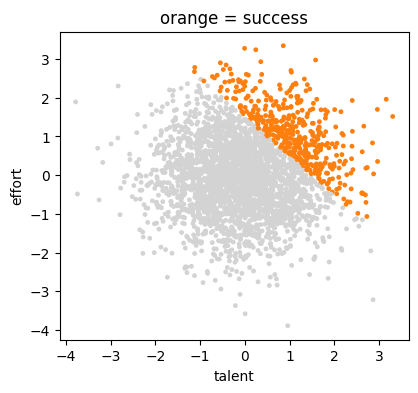

In [53]:
talent = rng.normal(size=N_sim)
effort = rng.normal(size=N_sim)
success = (talent + effort) > 1.5

corr_te = np.corrcoef(talent, effort)[0, 1]
corr_te_s = np.corrcoef(talent[success], effort[success])[0, 1]
print(f"corr(talent, effort)             = {corr_te:.3f}")
print(f"corr(talent, effort | success)   = {corr_te_s:.3f}")
check("independent overall", corr_te, 0.0, tol=0.02)

idx = rng.choice(N_sim, 3000, replace=False)
plt.figure(figsize=(4.5, 4))
plt.scatter(talent[idx], effort[idx], c=np.where(success[idx], "tab:orange", "lightgray"), s=6)
plt.xlabel("talent")
plt.ylabel("effort")
plt.title("orange = success")
plt.show()

**Q18.** Among successful people the correlation is strongly negative. Explain in one sentence.

> **Answer.** If someone succeeded with low talent, the success must be explained by high effort (and vice versa): conditioning on a common effect makes its causes dependent.

### 🧪 Practice 6 — The sprinkler network
*Slide: Example: Cloudy / Sprinkler / Rain / WetGrass* with these (new) tables:

| quantity | value |
|---|---|
| $p(C=1)$ | 0.5 |
| $p(S=1\mid C=0),\ p(S=1\mid C=1)$ | 0.5, 0.1 |
| $p(R=1\mid C=0),\ p(R=1\mid C=1)$ | 0.2, 0.8 |
| $p(W=1\mid S,R)$ for $(S,R) = (0,0), (0,1), (1,0), (1,1)$ | 0.0, 0.9, 0.9, 0.99 |

1. Draw 200,000 samples by ancestral sampling (C first, then S and R, then W).
2. Estimate $p(R=1)$, $p(R=1\mid W=1)$ and $p(R=1\mid W=1, S=1)$ by counting samples.
3. Compare with the exact values (computed for you by enumeration).
4. Check $S \perp R \mid C$ from the samples.

In [54]:
pC = 0.5
pS = {0: 0.5, 1: 0.1}                                   # p(S=1 | C=c)
pR = {0: 0.2, 1: 0.8}                                   # p(R=1 | C=c)
pW = {(0, 0): 0.0, (0, 1): 0.9, (1, 0): 0.9, (1, 1): 0.99}   # p(W=1 | S=s, R=r)

# exact answers by enumerating all 16 combinations: p(C,S,R,W) = p(C) p(S|C) p(R|C) p(W|S,R)
from itertools import product as all_combos


def joint(c, s, r, w):
    pc = pC if c else 1 - pC
    ps = pS[c] if s else 1 - pS[c]
    pr = pR[c] if r else 1 - pR[c]
    pw = pW[(s, r)] if w else 1 - pW[(s, r)]
    return pc * ps * pr * pw


def exact(query, given=lambda c, s, r, w: True):
    num = sum(joint(*v) for v in all_combos([0, 1], repeat=4) if query(*v) and given(*v))
    den = sum(joint(*v) for v in all_combos([0, 1], repeat=4) if given(*v))
    return num / den


exact_R = exact(lambda c, s, r, w: r == 1)
exact_R_W = exact(lambda c, s, r, w: r == 1, lambda c, s, r, w: w == 1)
exact_R_WS = exact(lambda c, s, r, w: r == 1, lambda c, s, r, w: w == 1 and s == 1)

In [55]:
N_sp = 200_000
C = rng.random(N_sp) < pC
S = rng.random(N_sp) < np.where(C, pS[1], pS[0])
R = rng.random(N_sp) < np.where(C, pR[1], pR[0])
pW_table = np.array([[pW[(0, 0)], pW[(0, 1)]],
                     [pW[(1, 0)], pW[(1, 1)]]])         # pW_table[s, r]
W = rng.random(N_sp) < pW_table[S.astype(int), R.astype(int)]

est_R = R.mean()
est_R_W = R[W].mean()
est_R_WS = R[W & S].mean()
display(pd.DataFrame({"sampled": [est_R, est_R_W, est_R_WS], "exact": [exact_R, exact_R_W, exact_R_WS]},
                     index=["p(R=1)", "p(R=1 | W=1)", "p(R=1 | W=1, S=1)"]))
check("p(R=1 | W=1)", est_R_W, exact_R_W, tol=0.01)
check("p(R=1 | W=1, S=1)", est_R_WS, exact_R_WS, tol=0.01)

print(f"corr(S, R)         = {np.corrcoef(S, R)[0, 1]:.3f}")
print(f"corr(S, R | C = 1) = {np.corrcoef(S[C], R[C])[0, 1]:.3f}")

,sampled,exact
p(R=1),0.5005,0.5000
p(R=1 | W=1),0.7078,0.7079
"p(R=1 | W=1, S=1)",0.3206,0.3204


✅ p(R=1 | W=1)
✅ p(R=1 | W=1, S=1)
corr(S, R)         = -0.263
corr(S, R | C = 1) = -0.001


**Q19.** (a) Why does learning that the sprinkler was on *lower* the probability of rain, given wet grass? (b) $S$ and $R$ are correlated overall but not given $C$. Which structure is this?

> **Answer.** (a) Explaining away: W is a collider of S and R. The sprinkler already explains the wet grass, so we need rain less. (b) A fork: Cloudy is a common cause of both (cloudy → less sprinkler, more rain).

---
# Part 7 (Optional) — Looking Ahead: Bayesian Learning
*Slide: Looking Ahead (Optional): Bayesian Learning*

Treat $\theta = p(H)$ itself as uncertain. With a Beta prior $\theta \sim \text{Beta}(a, b)$ and
Bernoulli flips, the posterior is again a Beta:
$$\theta\mid D \sim \text{Beta}(a + \#H,\; b + \#T), \qquad p(\text{next} = H\mid D) = \frac{a + \#H}{a + b + N}.$$

In [56]:
a0, b0 = 1, 1                                    # Beta(1, 1) = uniform prior on theta
a_post = a0 + n_heads
b_post = b0 + n_tails
post_theta = beta(a_post, b_post)
print(f"posterior Beta({a_post}, {b_post}),  mean = {post_theta.mean():.3f},  MLE = {n_heads / len(flips):.3f}")
check("posterior mean", post_theta.mean(), 9 / 14)

post_hhh = beta(a0 + 3, b0 + 0)
print(f"p(next = H | HHH) = {post_hhh.mean():.3f}   (Laplace smoothing gave (3+1)/(3+2) = 0.8)")
check("Bayesian = Laplace", post_hhh.mean(), 0.8)

posterior Beta(9, 5),  mean = 0.643,  MLE = 0.667
✅ posterior mean
p(next = H | HHH) = 0.800   (Laplace smoothing gave (3+1)/(3+2) = 0.8)
✅ Bayesian = Laplace


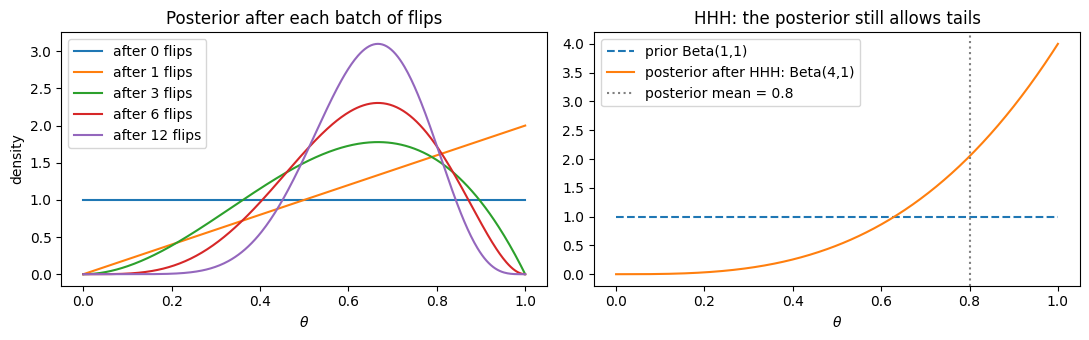

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
th = np.linspace(0, 1, 400)
for t in [0, 1, 3, 6, 12]:                        # posterior after the first t flips of HTHHHTHHTHTH
    h = flips[:t].count("H")
    axes[0].plot(th, beta(a0 + h, b0 + t - h).pdf(th), label=f"after {t} flips")
axes[0].set(xlabel=r"$\theta$", ylabel="density", title="Posterior after each batch of flips")
axes[0].legend()

axes[1].plot(th, beta(a0, b0).pdf(th), "--", label="prior Beta(1,1)")
axes[1].plot(th, post_hhh.pdf(th), label="posterior after HHH: Beta(4,1)")
axes[1].axvline(post_hhh.mean(), c="gray", ls=":", label="posterior mean = 0.8")
axes[1].set(xlabel=r"$\theta$", title="HHH: the posterior still allows tails")
axes[1].legend()
plt.tight_layout()
plt.show()

### 🧪 Practice 7 — A mint prior
A coin from a mint is almost surely close to fair. Use the prior $\text{Beta}(50, 50)$ and the data
`HTHHHTHHTHTH`. What is $p(\text{next} = H\mid D)$? Compare it with the MLE (0.667) and with
the uniform prior (0.643).

In [58]:
post_mint = beta(50 + n_heads, 50 + n_tails)
print(f"p(next = H | D) = {post_mint.mean():.3f}")
check("mint prior", post_mint.mean(), 58 / 112)

p(next = H | D) = 0.518
✅ mint prior


**Q20.** Why does the mint prior barely move with 12 flips? How is this like Part 2?

> **Answer.** Beta(50, 50) acts like 100 pseudo-flips that were already seen, so 12 real flips change it little (0.5 → 0.518). It is the same message as Part 2: a strong prior needs a lot of data to be overturned.

> **Next:** when the posterior has no closed form (most real models), we approximate it with MCMC
> or variational inference, e.g. with Pyro. See the *Probabilistic Inference* lecture
> (`../probabilistic_inference/prob_infer.ipynb`).